# 03 · Working with Images (Pillow)

**Module 14 – Working with Data & the Web** · Estimated time: 45 min

> Based on 📗 *Overview of Working with Images*, extended with thumbnails, colour modes, filters, `ImageOps`, drawing text/shapes, enhancement, batch processing, and the ⚠️ Pillow 10 API change (`ANTIALIAS` removed).

### 🎯 What you will learn
- Opening images; size, mode, format
- Cropping, copying & pasting, resizing, rotating
- Transparency (`putalpha`, masks), saving in different formats
- Thumbnails, colour modes (RGB/RGBA/L), filters, `ImageOps`, `ImageEnhance`, `ImageDraw`
- Batch-processing a folder of images

Install: `pip install pillow` (the maintained fork of PIL; you still `import PIL`).

In [1]:
from PIL import Image, ImageFilter, ImageOps, ImageEnhance, ImageDraw
import PIL
print("Pillow", PIL.__version__)

def preview(img, max_size=350):
    """Show a small copy so the notebook stays light (the original is untouched)."""
    small = img.copy()
    small.thumbnail((max_size, max_size))
    return small

Pillow 13.0.0


## 1. Opening images (📗)

<class 'PIL.JpegImagePlugin.JpegImageFile'>


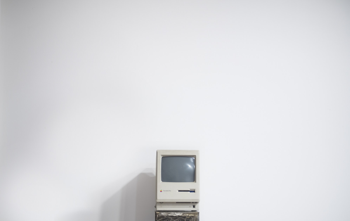

In [2]:
mac = Image.open("example.jpg")
print(type(mac))                 # a specialised PIL image class
preview(mac)                     # in Jupyter, an image as the last line is displayed. Elsewhere: mac.show()

In [3]:
print(mac.size)                  # (width, height)
print(mac.filename, mac.format, mac.format_description, mac.mode)

(1993, 1257)
example.jpg JPEG JPEG (ISO 10918) RGB


## 2. Cropping (📗)

`crop((left, top, right, bottom))`: coordinates start at the **top-left (0, 0)**.

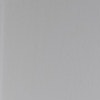

In [4]:
preview(mac.crop((0, 0, 100, 100)))

(1950, 1300)


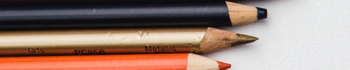

In [5]:
pencils = Image.open("pencils.jpg")
print(pencils.size)
x, y = 0, 0
w, h = 1950 / 3, 1300 / 10          # about 1/3 across, 1/10 down
preview(pencils.crop((x, y, w, h)))

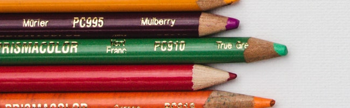

In [6]:
# The bottom pencils
preview(pencils.crop((0, 1100, 1950 / 3, 1300)))

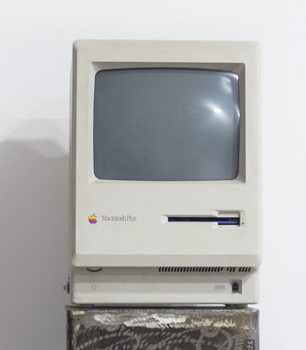

In [7]:
# Crop the computer from the middle of the Mac image
halfway = 1993 / 2
x, w = halfway - 200, halfway + 200
y, h = 800, 1257
computer = mac.crop((x, y, w, h))
preview(computer)

## 3. Copying and pasting (📗)

`paste()` modifies the image **in place**:

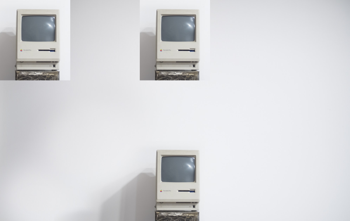

In [8]:
mac = Image.open("example.jpg")
mac.paste(im=computer, box=(0, 0))
mac.paste(im=computer, box=(796, 0))
preview(mac)

## 4. Resizing (📗)

(664, 419)


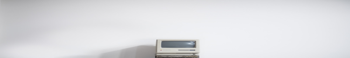

In [9]:
mac = Image.open("example.jpg")
w, h = mac.size                       # careful: size is (width, height)
small = mac.resize((w // 3, h // 3))  # returns a NEW image; for a permanent change reassign: mac = mac.resize(...)
print(small.size)
preview(mac.resize((3000, 500)))      # resize ignores the aspect ratio → distorted

✅ To keep the aspect ratio, use `thumbnail()` (in place, never enlarges) or `ImageOps.contain()`:

In [10]:
thumb = mac.copy()
thumb.thumbnail((300, 300))
print(thumb.size)
print(ImageOps.contain(mac, (300, 300)).size)
print(ImageOps.fit(mac, (300, 300)).size)            # crop to fill exactly 300×300

(300, 189)
(300, 189)
(300, 300)


> ⚠️ **Removed in Pillow 10 (2023):** `Image.ANTIALIAS` (and `Image.LINEAR`, `Image.CUBIC`). Older tutorials use `img.resize(size, Image.ANTIALIAS)`, which now raises `AttributeError`. Use `Image.Resampling.LANCZOS` (best for downscaling), `BICUBIC`, `BILINEAR` or `NEAREST`:

In [11]:
hq = mac.resize((400, 252), Image.Resampling.LANCZOS)
print(hq.size, hasattr(Image, "ANTIALIAS"))

(400, 252) False


## 5. Rotating and flipping (📗)

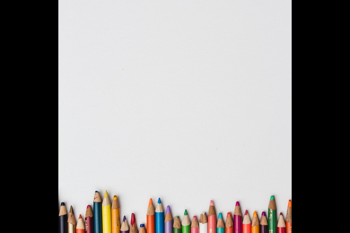

In [12]:
preview(pencils.rotate(90))                       # canvas stays the same size → corners cut off

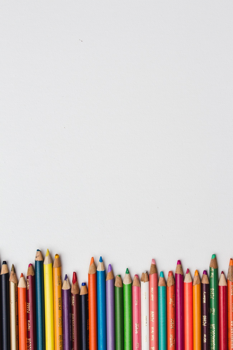

In [13]:
preview(pencils.rotate(90, expand=True))          # expand=True enlarges the canvas to fit

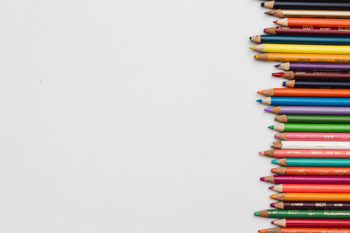

In [14]:
preview(pencils.transpose(Image.Transpose.FLIP_LEFT_RIGHT))   # mirror image

## 6. Colour modes & transparency (📗)

| Mode | Meaning |
|---|---|
| `RGB` | red, green, blue (0–255 each) |
| `RGBA` | + **alpha** (transparency: 0 = invisible, 255 = opaque) |
| `L` | grayscale |
| `P` | palette-based (GIF/PNG) |

RGB P


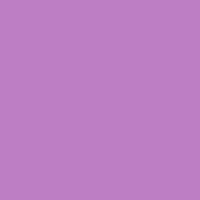

In [15]:
red = Image.open("red_color.jpg")
blue = Image.open("blue_color.png")
print(red.mode, blue.mode)        # RGB and P (palette)
blue = blue.convert("RGBA")       # ⚠️ see note below
red.putalpha(128)                 # make it 50% transparent (RGB → RGBA)
blue.putalpha(128)
blue.paste(red, box=(0, 0), mask=red)    # the mask uses red's alpha channel
blue                              # → purple-ish

> ⚠️ **Changed in recent Pillow versions:** the bootcamp calls `putalpha()` directly on the palette-mode (`P`) `blue_color.png`. Current Pillow turns that into mode `PA`, which **can't be saved as PNG** (`OSError: cannot write mode PA as PNG`). Convert palette images with `.convert("RGBA")` before adding transparency.

L


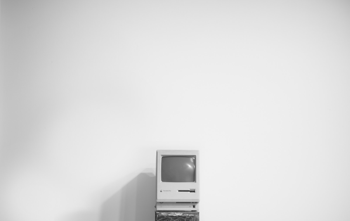

In [16]:
print(Image.open("example.jpg").convert("L").mode)
preview(Image.open("example.jpg").convert("L"))      # grayscale

## 7. Saving images (📗)

The format is taken from the file extension:

In [17]:
blue.save("purple.png")
purple = Image.open("purple.png")
print(purple.size, purple.mode)

small.convert("RGB").save("mac_small.jpg", quality=85, optimize=True)   # JPEG has no alpha → convert to RGB
small.save("mac_small.webp", quality=80)                                # modern format, smaller files
import os
print({f: os.path.getsize(f) for f in ["mac_small.jpg", "mac_small.webp"]})

(200, 200) RGBA


{'mac_small.jpg': 9125, 'mac_small.webp': 2918}


## 8. Filters, `ImageOps` and enhancement

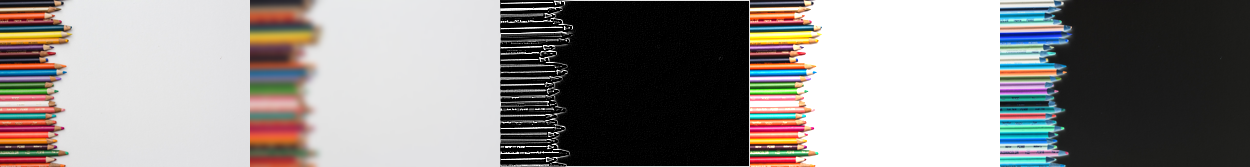

In [18]:
base = preview(Image.open("pencils.jpg"), 250)
blurred = base.filter(ImageFilter.GaussianBlur(3))
edges = base.convert("L").filter(ImageFilter.FIND_EDGES)
sharp = ImageEnhance.Sharpness(base).enhance(3)
bright = ImageEnhance.Brightness(base).enhance(1.5)
inverted = ImageOps.invert(base)

# Put them side by side on one canvas
tiles = [base, blurred, edges.convert("RGB"), bright, inverted]
canvas = Image.new("RGB", (sum(t.width for t in tiles), base.height), "white")
x = 0
for t in tiles:
    canvas.paste(t, (x, 0))
    x += t.width
canvas

## 9. Drawing shapes and text

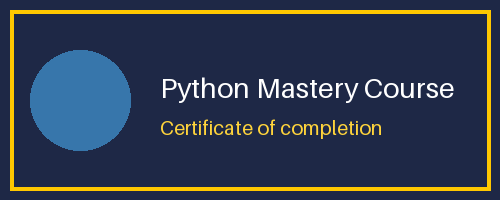

In [19]:
card = Image.new("RGB", (500, 200), (30, 40, 70))
draw = ImageDraw.Draw(card)
draw.rectangle((10, 10, 490, 190), outline=(255, 200, 0), width=4)
draw.ellipse((30, 50, 130, 150), fill=(55, 118, 171))
draw.text((160, 70), "Python Mastery Course", fill="white", font_size=28)   # font_size: Pillow ≥ 10.1
draw.text((160, 115), "Certificate of completion", fill=(255, 212, 59), font_size=20)
card

## 10. Example: the 📗 image exercise (reveal a hidden message)

The word matrix hides a message; overlay a semi-transparent mask resized to the same size:

(1015, 559) (505, 251)


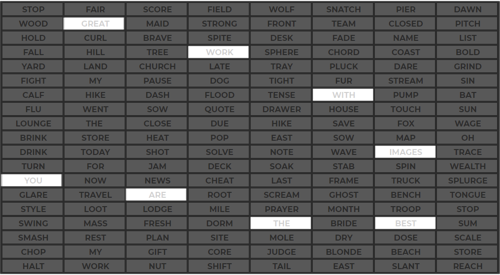

In [20]:
words = Image.open("word_matrix.png")
mask = Image.open("mask.png")
print(words.size, mask.size)
mask = mask.resize(words.size)
mask.putalpha(200)
words.paste(mask, (0, 0), mask)
preview(words, 500)

## 11. Batch processing a folder

In [21]:
from pathlib import Path

out = Path("thumbnails")
out.mkdir(exist_ok=True)
for path in Path(".").glob("*.jpg"):
    with Image.open(path) as img:              # images support `with` (closes the file)
        img.thumbnail((200, 200))
        img.save(out / f"{path.stem}_thumb.jpg")
print(sorted(p.name for p in out.iterdir()))

['example_thumb.jpg', 'mac_small_thumb.jpg', 'pencils_thumb.jpg', 'red_color_thumb.jpg']


## 12. Reading EXIF metadata (photos from phones/cameras)

```python
from PIL import ExifTags
img = Image.open("photo_from_phone.jpg")
for tag_id, value in img.getexif().items():
    print(ExifTags.TAGS.get(tag_id, tag_id), value)
img = ImageOps.exif_transpose(img)      # fix sideways phone photos automatically
```

## 📝 Summary
- `Image.open`, `.size`, `.mode`, `.crop()`, `.paste()` (in place), `.resize()` (new image), `.rotate(expand=True)`.
- Keep aspect ratio with `thumbnail()` / `ImageOps.contain()`; use `Image.Resampling.LANCZOS` (⚠️ not `ANTIALIAS`).
- Transparency via RGBA, `putalpha`, and `paste(..., mask=...)`.
- `ImageFilter`, `ImageOps`, `ImageEnhance`, `ImageDraw` for effects and drawing.
- `save()` picks the format from the extension; JPEG needs RGB.

## 🏋️ Practice (📗 Image Exercise in `exercises/`)
1. Create a 300×300 square thumbnail of `pencils.jpg` (crop to fill).
2. Make a grayscale, blurred version of `example.jpg` and save it as PNG.
3. Add a semi-transparent watermark text "© 2026" to the bottom-right corner of an image.

<details><summary>Show solutions</summary>

```python
from PIL import Image, ImageOps, ImageFilter, ImageDraw

ImageOps.fit(Image.open("pencils.jpg"), (300, 300)).save("square.jpg")

Image.open("example.jpg").convert("L").filter(ImageFilter.GaussianBlur(4)).save("gray_blur.png")

img = Image.open("example.jpg").convert("RGBA")
layer = Image.new("RGBA", img.size, (0, 0, 0, 0))
d = ImageDraw.Draw(layer)
d.text((img.width - 260, img.height - 80), "© 2026", fill=(255, 255, 255, 140), font_size=60)
Image.alpha_composite(img, layer).convert("RGB").save("watermarked.jpg")
```
</details>